Re-zipped exploded checkpoint into: /kaggle/working/dino_mixed_vial_reconstructed.pt
Using checkpoint: /kaggle/working/dino_mixed_vial_reconstructed.pt
Checkpoint config: {'category': 'vial', 'ORIG_SIZE': 448, 'TILE_SIZE': 224, 'TILE_STRIDE': 112, 'teacher': 'dinov2_vitb14 layers (6,11)'}
Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vitb14/dinov2_vitb14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vitb14_pretrain.pth


100%|██████████| 330M/330M [00:00<00:00, 351MB/s] 


Model reconstructed. Teacher embed_dim=1536, tile grid=16x16, tokens/tile=256
Using mask: /kaggle/input/datasets/arhaan1234/mv-tech-ad2/mvtec_ad_2/vial/test_public/ground_truth/bad/000_shift_4_mask.png


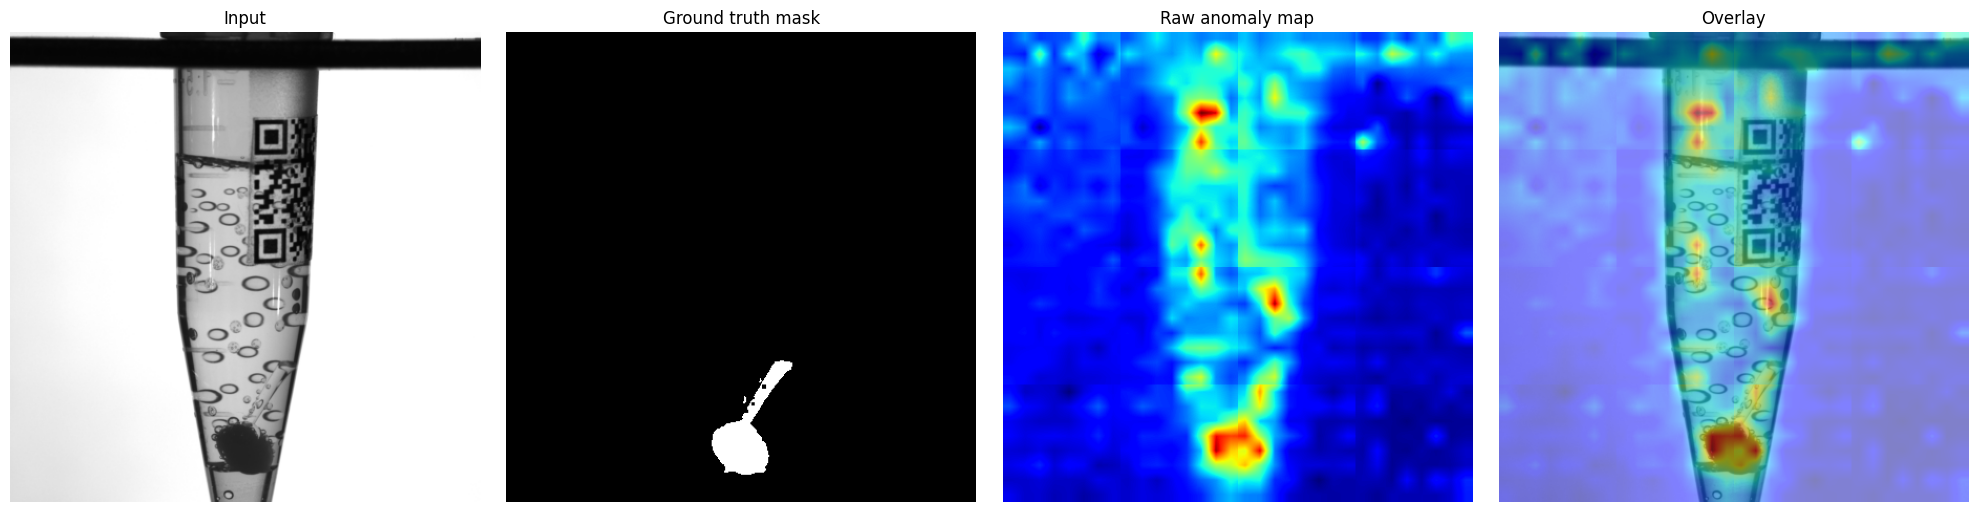

Saved featured-sample figure to /kaggle/working/figures/vial_000_shift_4_detail.png


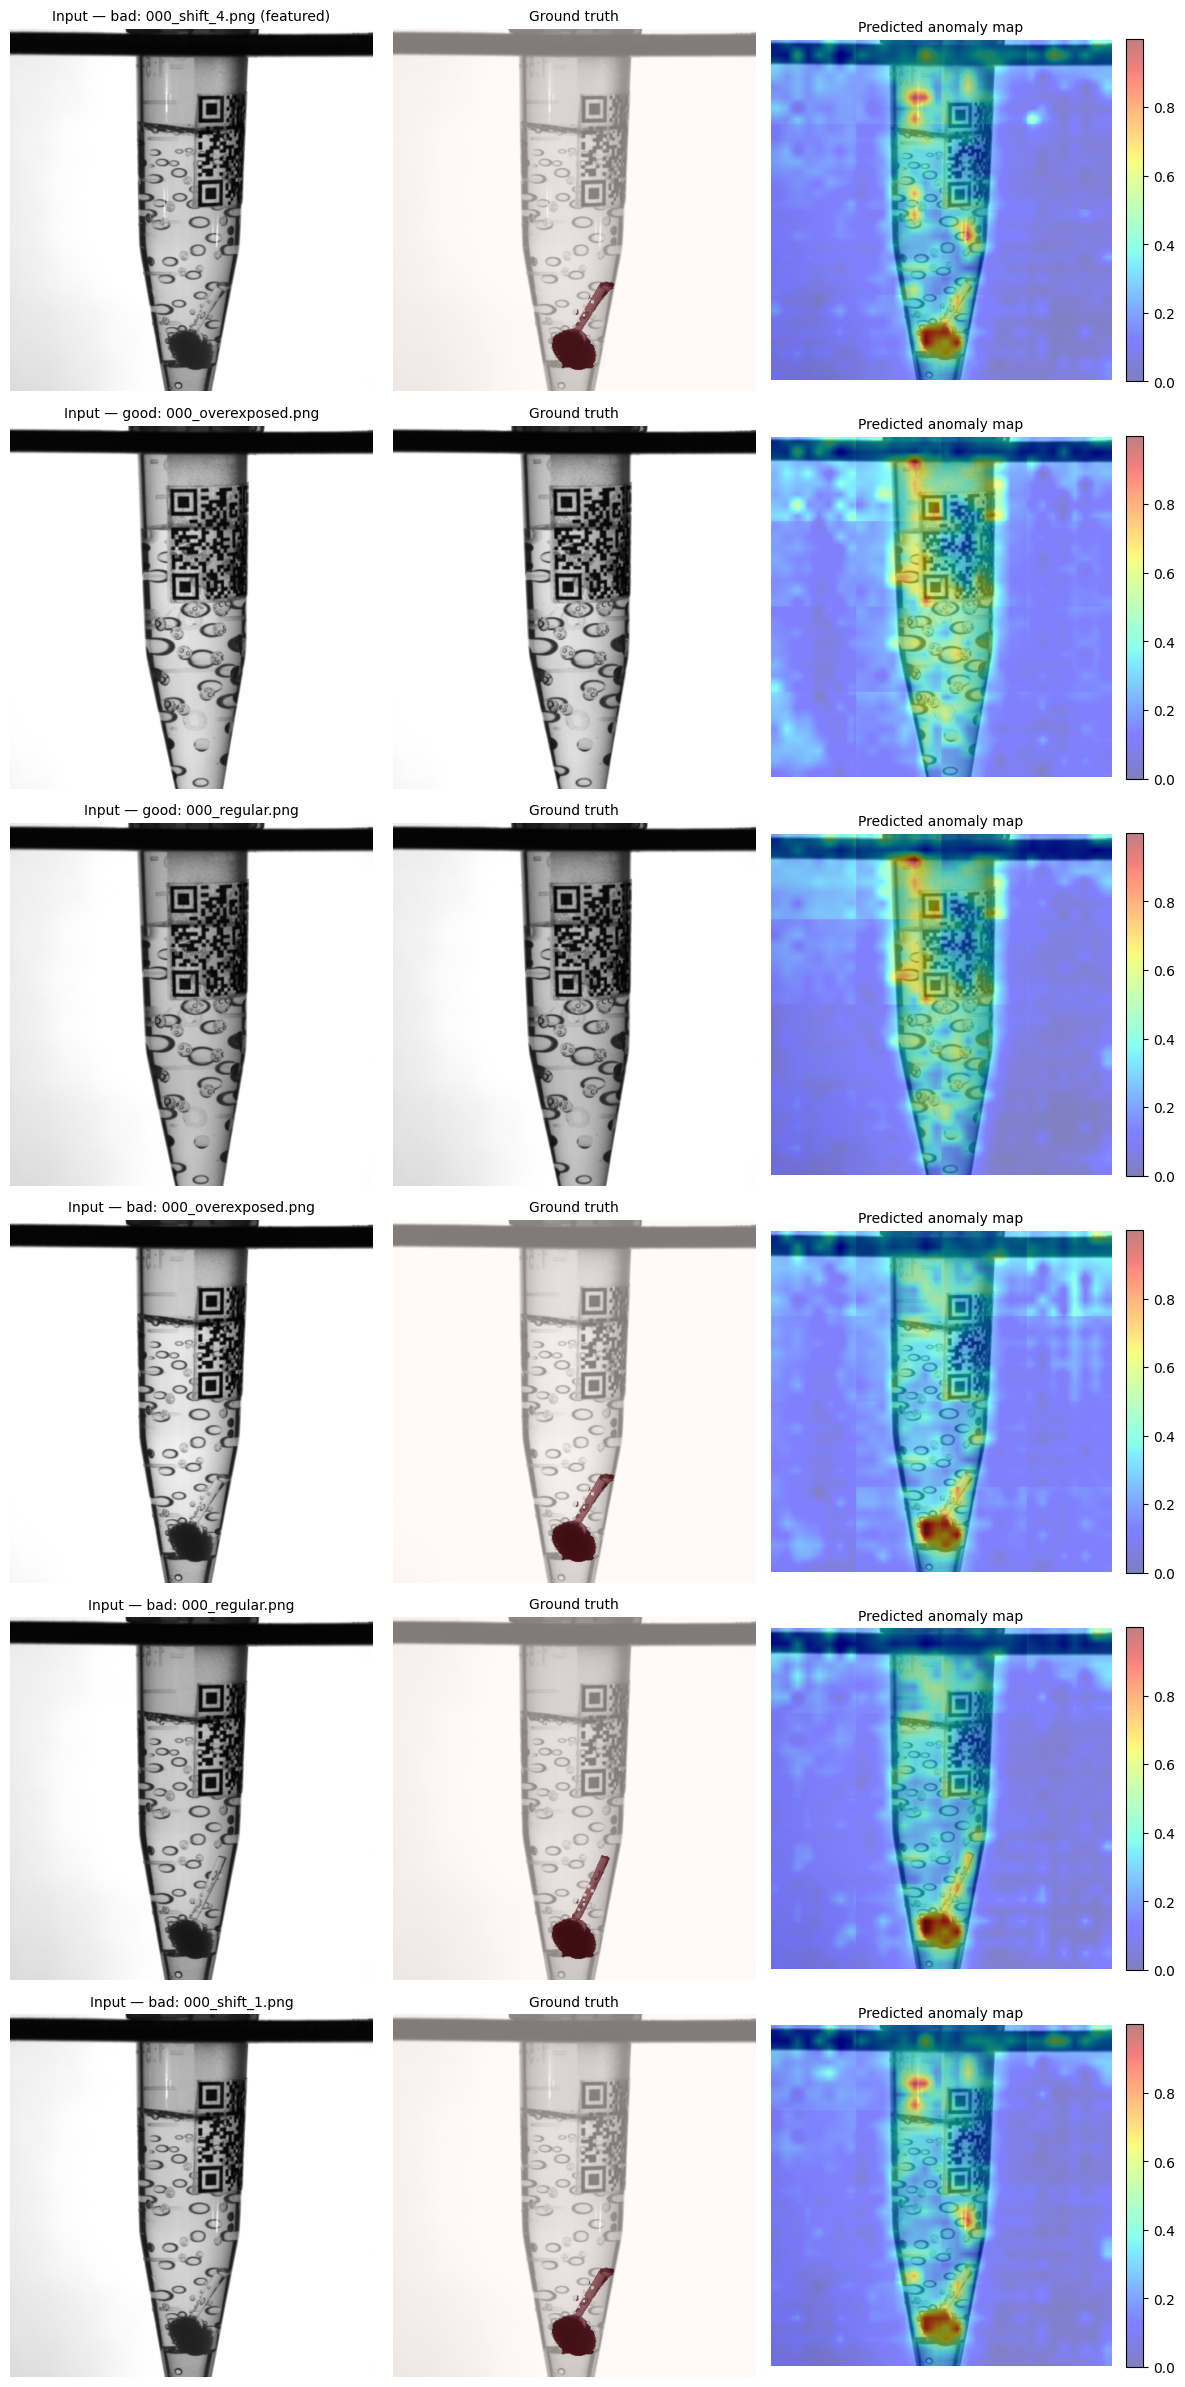

Saved grid figure to /kaggle/working/figures/vial_anomaly_visualization_grid.png


In [4]:
# ============================================================
# Anomaly-map visualization for your trained Vial model
# ============================================================
# CHANGED: earlier version of this script assumed the checkpoint came from
# dts_vial_lighting_v2.py (single-layer teacher, raw-pixel-patch-embed student, 518px
# tiles). Loading the actual checkpoint showed a different config:
#   {'category': 'vial', 'ORIG_SIZE': 448, 'TILE_SIZE': 224, 'TILE_STRIDE': 112,
#    'teacher': 'dinov2_vitb14 layers (6,11)'}
# That matches the dino_wallplugs_896.py / dino_multicat.py architecture instead: a
# TWO-layer concatenated DINOv2 teacher, and a student that takes the TEACHER'S OWN
# tokens as input and runs them through a bottleneck autoencoder (down_proj -> transformer
# blocks -> up_proj) — not the raw-pixel-distillation student. This script now rebuilds
# THAT architecture to match the actual weights, and runs the same average-stitch +
# top-0.5%-mean tiled inference already fixed in dino_wallplugs_896.py, since that's the
# most seam-resistant scoring available for this architecture.
# ============================================================
import os, glob, shutil
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_PATH = "/kaggle/input/datasets/arhaan1234/mv-tech-ad2/mvtec_ad_2"
CATEGORY = "vial"

MODEL_DIR = "/kaggle/input/datasets/jindwork/vial-model/dino_mixed_vial"
FEATURED_BAD_IMAGE = "/kaggle/input/datasets/arhaan1234/mv-tech-ad2/mvtec_ad_2/vial/test_public/bad/000_shift_4.png"
OUT_DIR = "/kaggle/working/figures"
os.makedirs(OUT_DIR, exist_ok=True)

N_GOOD_SAMPLES = 2
N_BAD_SAMPLES = 3


# ============================================================
# CELL — Re-zip the checkpoint. Kaggle auto-extracts compressed dataset uploads, so a
# .pt file (itself a zip archive internally) ends up "exploded" into data.pkl, version,
# byteorder, data/0, data/1, ... as separate files in a folder. Re-zip them back into a
# single .pt so torch.load can read it normally — the internal top-level folder name
# doesn't need to match anything specific, only be internally consistent, which it
# already is.
# ============================================================
def resolve_ckpt_path(path):
    if os.path.isfile(path):
        return path
    if not os.path.isdir(path):
        raise FileNotFoundError(f"{path} does not exist. Check the dataset is attached "
                                 f"and the path is right.")
    pt_files = sorted(glob.glob(os.path.join(path, "**", "*.pt"), recursive=True))
    if pt_files:
        return pt_files[0]
    # Looks like an exploded torch-zip checkpoint (data.pkl + data/ subfolder) — re-zip it.
    if os.path.exists(os.path.join(path, "data.pkl")):
        parent_dir = os.path.dirname(path)
        folder_name = os.path.basename(path)
        rebuilt_stem = os.path.join("/kaggle/working", f"{folder_name}_reconstructed")
        archive_path = shutil.make_archive(rebuilt_stem, "zip", root_dir=parent_dir, base_dir=folder_name)
        rebuilt_path = rebuilt_stem + ".pt"
        shutil.move(archive_path, rebuilt_path)
        print(f"Re-zipped exploded checkpoint into: {rebuilt_path}")
        return rebuilt_path
    raise FileNotFoundError(f"No .pt file or exploded-checkpoint contents (data.pkl) found under {path}.")

CKPT_PATH = resolve_ckpt_path(MODEL_DIR)
print(f"Using checkpoint: {CKPT_PATH}")


# ============================================================
# CELL — Dataset / tiling / normalization utilities (identical to dino_wallplugs_896.py)
# ============================================================
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def load_rgb_square(path, resize):
    """CenterCrop-after-Resize, matching MVTecAD2Dataset's transform exactly."""
    img = Image.open(path).convert("RGB")
    w, h = img.size
    scale = resize / min(w, h)
    img = img.resize((max(round(w * scale), resize), max(round(h * scale), resize)), Image.BILINEAR)
    w, h = img.size
    left, top = (w - resize) // 2, (h - resize) // 2
    img = img.crop((left, top, left + resize, top + resize))
    return torch.from_numpy(np.array(img)).float().permute(2, 0, 1) / 255.0

def load_mask_square(path, resize):
    if path is None or not os.path.exists(path):
        return np.zeros((resize, resize), dtype=np.uint8)
    img = Image.open(path).convert("L")
    w, h = img.size
    scale = resize / min(w, h)
    img = img.resize((max(round(w * scale), resize), max(round(h * scale), resize)), Image.NEAREST)
    w, h = img.size
    left, top = (w - resize) // 2, (h - resize) // 2
    img = img.crop((left, top, left + resize, top + resize))
    return (np.array(img) > 127).astype(np.uint8)

def imagenet_normalize(img):
    return (img - IMAGENET_MEAN.to(img.device)) / IMAGENET_STD.to(img.device)

def extract_tiles(image_tensor, tile_size, stride):
    _, H, W = image_tensor.shape
    tiles, positions = [], []
    for y in range(0, max(H - tile_size, 0) + 1, stride):
        for x in range(0, max(W - tile_size, 0) + 1, stride):
            tile = image_tensor[:, y:y+tile_size, x:x+tile_size]
            if tile.shape[1] == tile_size and tile.shape[2] == tile_size:
                tiles.append(tile)
                positions.append((y, x))
    if (H - tile_size) % stride != 0:
        for x_pos in [p[1] for p in positions if p[0] == positions[0][0]] or [0]:
            tiles.append(image_tensor[:, H-tile_size:H, x_pos:x_pos+tile_size])
            positions.append((H-tile_size, x_pos))
    if (W - tile_size) % stride != 0:
        for y_pos in sorted(set(p[0] for p in positions)):
            tiles.append(image_tensor[:, y_pos:y_pos+tile_size, W-tile_size:W])
            positions.append((y_pos, W-tile_size))
    return tiles, positions

def find_mask_for(bad_image_path, gt_dir):
    stem = os.path.splitext(os.path.basename(bad_image_path))[0]
    candidates = [os.path.join(gt_dir, stem + "_mask.png"), os.path.join(gt_dir, stem + ".png")]
    for c in candidates:
        if os.path.exists(c):
            return c
    print(f"WARNING: no ground-truth mask found for {bad_image_path} (tried {candidates}).")
    return None


# ============================================================
# CELL — Architecture matching the checkpoint (DINOv2 2-layer teacher + bottleneck
# autoencoder student), rebuilt from the config saved inside the checkpoint itself.
# ============================================================
ckpt = torch.load(CKPT_PATH, map_location=DEVICE, weights_only=False)
cfg = ckpt["config"]
print("Checkpoint config:", cfg)

ORIG_SIZE   = cfg["ORIG_SIZE"]
TILE_SIZE   = cfg["TILE_SIZE"]
TILE_STRIDE = cfg["TILE_STRIDE"]
DINO_PATCH  = 14
GRID_SIZE   = TILE_SIZE // DINO_PATCH
NUM_TOKENS  = GRID_SIZE ** 2

class DINOv2MultiLayerExtractor(nn.Module):
    def __init__(self, model_name="dinov2_vitb14", layers=(6, 11)):
        super().__init__()
        self.dino = torch.hub.load('facebookresearch/dinov2', model_name)
        self.dino.eval()
        for p in self.dino.parameters():
            p.requires_grad = False
        self.layers = layers
        self.embed_dim = self.dino.embed_dim * len(layers)

    @torch.no_grad()
    def forward(self, x):
        feats = self.dino.get_intermediate_layers(x, n=self.layers, reshape=False)
        return torch.cat(feats, dim=-1)


def make_transformer_block(dim, heads, mlp_ratio=4.0):
    return nn.TransformerEncoderLayer(
        d_model=dim, nhead=heads, dim_feedforward=int(dim * mlp_ratio),
        dropout=0.0, activation="gelu", batch_first=True, norm_first=True,
    )

class TransformerStudent(nn.Module):
    def __init__(self, embed_dim, num_tokens=NUM_TOKENS, bottleneck_dim=128, depth=3, heads=4):
        super().__init__()
        self.down_proj = nn.Linear(embed_dim, bottleneck_dim)
        self.pos_embed = nn.Parameter(torch.zeros(1, num_tokens, bottleneck_dim))
        self.blocks = nn.ModuleList([make_transformer_block(bottleneck_dim, heads) for _ in range(depth)])
        self.norm = nn.LayerNorm(bottleneck_dim)
        self.up_proj = nn.Linear(bottleneck_dim, embed_dim)

    def forward(self, tokens):
        x = self.down_proj(tokens) + self.pos_embed
        for blk in self.blocks:
            x = blk(x)
        x = self.norm(x)
        return self.up_proj(x)


teacher = DINOv2MultiLayerExtractor(layers=(6, 11)).to(DEVICE)
student = TransformerStudent(embed_dim=teacher.embed_dim).to(DEVICE)
student.load_state_dict(ckpt["student_state_dict"])
student.eval()
print(f"Model reconstructed. Teacher embed_dim={teacher.embed_dim}, "
      f"tile grid={GRID_SIZE}x{GRID_SIZE}, tokens/tile={NUM_TOKENS}")


# ============================================================
# CELL — Tiled inference: average-stitched map + top-0.5%-mean score (the seam-resistant
# combination already fixed in dino_wallplugs_896.py — used here for consistency, since
# this is the same architecture/scoring family).
# ============================================================
TOPK_FRAC = 0.005

@torch.no_grad()
def compute_anomaly_map(image_path):
    img = load_rgb_square(image_path, resize=ORIG_SIZE)
    tiles, positions = extract_tiles(img, TILE_SIZE, TILE_STRIDE)

    acc = torch.zeros(ORIG_SIZE, ORIG_SIZE)
    cnt = torch.zeros(ORIG_SIZE, ORIG_SIZE)

    for tile, (y, x) in zip(tiles, positions):
        tile_batch = tile.unsqueeze(0).to(DEVICE)
        tile_norm = imagenet_normalize(tile_batch)
        target_tokens = teacher(tile_norm)
        pred_tokens = student(target_tokens)
        target_norm = F.normalize(target_tokens, dim=-1)
        pred_norm = F.normalize(pred_tokens, dim=-1)
        err_per_token = 1 - (target_norm * pred_norm).sum(dim=-1)

        err_grid = err_per_token.reshape(1, GRID_SIZE, GRID_SIZE).unsqueeze(1)
        tile_map = F.interpolate(err_grid, size=(TILE_SIZE, TILE_SIZE),
                                  mode="bilinear", align_corners=False).squeeze().cpu()

        acc[y:y+TILE_SIZE, x:x+TILE_SIZE] += tile_map
        cnt[y:y+TILE_SIZE, x:x+TILE_SIZE] += 1.0

    cnt[cnt == 0] = 1.0
    full_map_np = (acc / cnt).numpy()
    img_display = img.permute(1, 2, 0).numpy()
    return img_display, full_map_np


# ============================================================
# CELL — Featured single-sample detail figure (input / GT / raw heatmap / overlay)
# ============================================================
class_path = os.path.join(DATA_PATH, CATEGORY)
gt_dir = os.path.join(class_path, "test_public", "ground_truth", "bad")

mask_path = find_mask_for(FEATURED_BAD_IMAGE, gt_dir)
print(f"Using mask: {mask_path}")

img_display, anomaly_map = compute_anomaly_map(FEATURED_BAD_IMAGE)
gt_mask = load_mask_square(mask_path, resize=ORIG_SIZE)
amap_norm = (anomaly_map - anomaly_map.min()) / (anomaly_map.max() - anomaly_map.min() + 1e-8)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(img_display); axes[0].set_title("Input"); axes[0].axis("off")
axes[1].imshow(gt_mask, cmap="gray"); axes[1].set_title("Ground truth mask"); axes[1].axis("off")
axes[2].imshow(amap_norm, cmap="jet"); axes[2].set_title("Raw anomaly map"); axes[2].axis("off")
axes[3].imshow(img_display)
axes[3].imshow(amap_norm, cmap="jet", alpha=0.5)
axes[3].set_title("Overlay"); axes[3].axis("off")
plt.tight_layout()

featured_stem = os.path.splitext(os.path.basename(FEATURED_BAD_IMAGE))[0]
single_out = os.path.join(OUT_DIR, f"vial_{featured_stem}_detail.png")
plt.savefig(single_out, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved featured-sample figure to {single_out}")


# ============================================================
# CELL — Grid figure: featured image + a few more good/bad samples
# ============================================================
good_dir = os.path.join(class_path, "test_public", "good")
bad_dir  = os.path.join(class_path, "test_public", "bad")

good_files = sorted(os.listdir(good_dir))[:N_GOOD_SAMPLES] if os.path.exists(good_dir) else []
bad_files_all = sorted([f for f in os.listdir(bad_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
featured_name = os.path.basename(FEATURED_BAD_IMAGE)
other_bad = [f for f in bad_files_all if f != featured_name][:N_BAD_SAMPLES]

samples = [(FEATURED_BAD_IMAGE, mask_path, 1, f"bad: {featured_name} (featured)")]
for f in good_files:
    samples.append((os.path.join(good_dir, f), None, 0, f"good: {f}"))
for f in other_bad:
    samples.append((os.path.join(bad_dir, f), find_mask_for(os.path.join(bad_dir, f), gt_dir), 1, f"bad: {f}"))

n_rows = len(samples)
fig, axes = plt.subplots(n_rows, 3, figsize=(12, 4 * n_rows))
if n_rows == 1:
    axes = axes[None, :]

for row, (img_path, mp, label, title) in enumerate(samples):
    img_disp, amap = compute_anomaly_map(img_path)
    gt = load_mask_square(mp, resize=ORIG_SIZE)
    amap_n = (amap - amap.min()) / (amap.max() - amap.min() + 1e-8)

    ax0, ax1, ax2 = axes[row]
    ax0.imshow(img_disp); ax0.set_title(f"Input — {title}", fontsize=10); ax0.axis("off")
    ax1.imshow(img_disp); ax1.imshow(gt, cmap="Reds", alpha=0.5 * (gt.max() > 0))
    ax1.set_title("Ground truth", fontsize=10); ax1.axis("off")
    ax2.imshow(img_disp)
    heat = ax2.imshow(amap_n, cmap="jet", alpha=0.5)
    ax2.set_title("Predicted anomaly map", fontsize=10); ax2.axis("off")
    fig.colorbar(heat, ax=ax2, fraction=0.046, pad=0.04)

plt.tight_layout()
grid_out = os.path.join(OUT_DIR, "vial_anomaly_visualization_grid.png")
plt.savefig(grid_out, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved grid figure to {grid_out}")

In [6]:
p = "/kaggle/input/datasets/jindwork/external-fabric/fabric-test-external2.jpg"
print(os.path.getsize(p), "bytes")
print(open(p, "rb").read(16))

3470345 bytes
b'\x00\x00\x00,ftypheic\x00\x00\x00\x00'


Checkpoint was an exploded folder -> re-zipped to /kaggle/working/dinov2_teacher_student_fabric_rezipped.pt
Using checkpoint key 'student_state_dict'
Checkpoint loaded (strict, key names match).


Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


Calibrating on 66 good + 90 defective test images...
good images : score median 0.4615  (range 0.4041-0.7064)
defective   : score median 0.5107  (range 0.4271-0.8070)
threshold (balanced / Youden) = 0.5720  -> catches 43% of defects, false-alarms on 6% of good
threshold (conservative, 95th pct of good) = 0.5915  -> catches 40% of defects


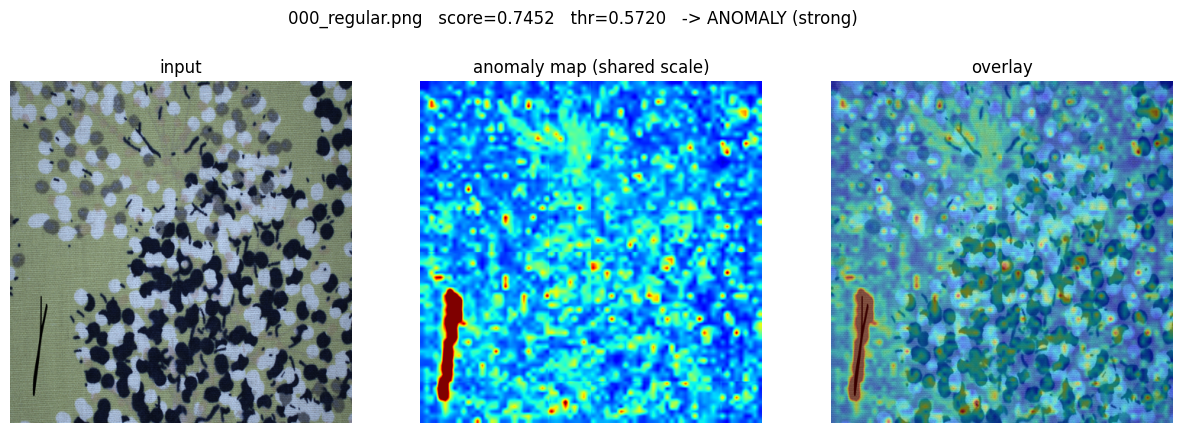

000_regular.png   score=0.7452   thr=0.5720   -> ANOMALY (strong)
saved: /kaggle/working/result_000_regular.png


In [2]:
# ============================================================
# Test the Fabric-design student (trained on Fabric) on your OWN photo(s).
# Paste into a Kaggle notebook cell (Internet ON, GPU recommended).
#
# What it does:
#   1. Loads the Fabric checkpoint (handles a normal .pt file OR Kaggle's
#      "exploded" checkpoint folder, and several checkpoint key layouts).
#   2. Builds the exact Fabric pipeline: image -> 1036x1036 square resize ->
#      518px tiles / stride 392 -> frozen DINOv2 ViT-B/14 final-layer tokens vs.
#      pixel-input student -> per-token cosine error -> AVG-stitched map.
#   3. Scores with the same rule as the paper's harness (map resized to 448,
#      10px border crop, mean of top-50 values).
#   4. A single score means nothing without a threshold, so it calibrates one
#      from the MVTec Fabric test_public good/bad images and then gives a
#      verdict for your photo(s) + a heatmap overlay.
# ============================================================
import os, glob, shutil
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt
!pip install -q pillow-heif
from pillow_heif import register_heif_opener
register_heif_opener()

# ---------------- EDIT THESE ----------------
CKPT_PATH  = "/kaggle/input/datasets/jindwork/dino-fabric/dinov2_teacher_student_fabric"
# a single image file OR a folder of images (upload via Add Input -> Upload, then paste its path)
IMAGE_PATH = "/kaggle/input/datasets/jindwork/fabric-annotated"
DATASET_ROOT = "/kaggle/input/datasets/arhaan1234/mv-tech-ad2/mvtec_ad_2"
CALIBRATE = True        # set False to skip threshold calibration (then only the raw score/heatmap are shown)
# --------------------------------------------

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
TILE, STRIDE, SRC = 518, 392, 1036
PATCH, EMBED, DEPTH, HEADS = 14, 384, 4, 6
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

# ---------- 1. checkpoint: fix exploded folder, then load ----------
def resolve_ckpt(path):
    if os.path.isdir(path):
        pts = glob.glob(os.path.join(path, "**", "*.pt"), recursive=True) + \
              glob.glob(os.path.join(path, "**", "*.pth"), recursive=True)
        if pts:
            return pts[0]
        # Kaggle auto-extracted the .pt zip into loose files (data.pkl, data/0, ...) -> re-zip it
        parent, name = os.path.split(path.rstrip("/"))
        out_stem = f"/kaggle/working/{name}_rezipped"
        shutil.make_archive(out_stem, "zip", root_dir=parent, base_dir=name)
        os.replace(out_stem + ".zip", out_stem + ".pt")
        print(f"Checkpoint was an exploded folder -> re-zipped to {out_stem}.pt")
        return out_stem + ".pt"
    return path

ckpt_file = resolve_ckpt(CKPT_PATH)
raw = torch.load(ckpt_file, map_location="cpu")
state = raw
if isinstance(raw, dict):
    for k in ("student_state_dict", "student", "model", "state_dict", "model_state_dict"):
        if k in raw and isinstance(raw[k], dict):
            state = raw[k]; print(f"Using checkpoint key '{k}'"); break
state = {k.replace("module.", "", 1): v for k, v in state.items()}

class Student(nn.Module):
    def __init__(self):
        super().__init__()
        self.patch_embed = nn.Conv2d(3, EMBED, kernel_size=PATCH, stride=PATCH)
        n_patches = (TILE // PATCH) ** 2
        self.pos_embed = nn.Parameter(torch.zeros(1, n_patches, EMBED))
        layer = nn.TransformerEncoderLayer(d_model=EMBED, nhead=HEADS, dim_feedforward=EMBED * 4, batch_first=True)
        self.blocks = nn.TransformerEncoder(layer, num_layers=DEPTH)
        self.head = nn.Linear(EMBED, 768)
    def forward(self, x):
        x = self.patch_embed(x).flatten(2).transpose(1, 2) + self.pos_embed
        return self.head(self.blocks(x))

student = Student()
try:
    student.load_state_dict(state, strict=True)
    print("Checkpoint loaded (strict, key names match).")
except RuntimeError as e:
    # Key names differ from this script's naming -> fall back to loading by position,
    # which is safe only if every tensor shape lines up in order.
    ck_items, md_items = list(state.items()), list(student.state_dict().items())
    if len(ck_items) == len(md_items) and all(a[1].shape == b[1].shape for a, b in zip(ck_items, md_items)):
        student.load_state_dict({b[0]: a[1] for a, b in zip(ck_items, md_items)})
        print("Key names differed; loaded by position (all shapes matched).")
    else:
        print("Could not match checkpoint to the Fabric student architecture.")
        print("Checkpoint keys:", [(k, tuple(v.shape)) for k, v in ck_items][:12], "...")
        raise e
student = student.to(DEVICE).eval()

dinov2 = torch.hub.load("facebookresearch/dinov2", "dinov2_vitb14").to(DEVICE).eval()
for p in dinov2.parameters(): p.requires_grad = False

# ---------- 2. anomaly map for one image ----------
def _coords(n, tile, stride):
    xs = list(range(0, n - tile + 1, stride))
    return xs + [n - tile] if xs[-1] != n - tile else xs
COORDS = [(y, x) for y in _coords(SRC, TILE, STRIDE) for x in _coords(SRC, TILE, STRIDE)]

def load_square(path, size=SRC):
    im = Image.open(path).convert("RGB").resize((size, size), Image.BILINEAR)
    return torch.from_numpy(np.array(im)).float().permute(2, 0, 1) / 255

@torch.no_grad()
def anomaly_map(path):
    x = (load_square(path) - MEAN) / STD
    acc = np.zeros((SRC, SRC), np.float32); cnt = np.zeros_like(acc)
    for i in range(0, len(COORDS), 8):
        cs = COORDS[i:i + 8]
        b = torch.stack([x[:, y:y + TILE, xx:xx + TILE] for y, xx in cs]).to(DEVICE)
        t = dinov2.forward_features(b)["x_norm_patchtokens"]
        s = student(b)
        err = 1 - F.cosine_similarity(s, t, dim=-1)
        g = int(err.shape[1] ** 0.5)
        err = F.interpolate(err.view(-1, 1, g, g), size=(TILE, TILE), mode="bilinear", align_corners=False)[:, 0].cpu().numpy()
        for (y, xx), m in zip(cs, err):
            acc[y:y + TILE, xx:xx + TILE] += m; cnt[y:y + TILE, xx:xx + TILE] += 1
    m = acc / cnt
    # same grid + scoring rule as the paper's report() harness: 448 grid, 10px border, mean of top-50
    m448 = F.interpolate(torch.from_numpy(m)[None, None], size=(448, 448), mode="bilinear",
                         align_corners=False, antialias=True)[0, 0].numpy()
    c = m448[10:-10, 10:-10].ravel()
    return m448, float(np.partition(c, -50)[-50:].mean())

# ---------- 3. calibrate a threshold from MVTec Fabric test_public ----------
thr_balanced = thr_conservative = vmax = None
if CALIBRATE:
    root = f"{DATASET_ROOT}/fabric/test_public"
    exts = (".png", ".jpg", ".jpeg")
    good = [f"{root}/good/{f}" for f in sorted(os.listdir(f"{root}/good")) if f.lower().endswith(exts)]
    bad = [f"{root}/bad/{f}" for f in sorted(os.listdir(f"{root}/bad")) if f.lower().endswith(exts)]
    print(f"Calibrating on {len(good)} good + {len(bad)} defective test images...")
    g_scores, b_scores, b_pix = [], [], []
    for p in good: g_scores.append(anomaly_map(p)[1])
    for p in bad:
        m, s = anomaly_map(p); b_scores.append(s); b_pix.append(m[::4, ::4].ravel())
    g_scores, b_scores = np.array(g_scores), np.array(b_scores)
    cand = np.unique(np.concatenate([g_scores, b_scores]))
    best, thr_balanced = -1, cand[0]
    for t in cand:   # Youden's J: best balance of catching defects vs. false alarms
        j = (b_scores >= t).mean() - (g_scores >= t).mean()
        if j > best: best, thr_balanced = j, t
    thr_conservative = float(np.percentile(g_scores, 95))   # flags only what exceeds 95% of good images
    vmax = float(np.percentile(np.concatenate(b_pix), 99.5))
    print(f"good images : score median {np.median(g_scores):.4f}  (range {g_scores.min():.4f}-{g_scores.max():.4f})")
    print(f"defective   : score median {np.median(b_scores):.4f}  (range {b_scores.min():.4f}-{b_scores.max():.4f})")
    print(f"threshold (balanced / Youden) = {thr_balanced:.4f}  -> catches {(b_scores>=thr_balanced).mean():.0%} of defects, "
          f"false-alarms on {(g_scores>=thr_balanced).mean():.0%} of good")
    print(f"threshold (conservative, 95th pct of good) = {thr_conservative:.4f}  -> catches {(b_scores>=thr_conservative).mean():.0%} of defects")

# ---------- 4. run on your photo(s) ----------
if os.path.isdir(IMAGE_PATH):
    imgs = sorted(p for p in glob.glob(os.path.join(IMAGE_PATH, "**", "*"), recursive=True)
                  if p.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".webp")))
else:
    imgs = [IMAGE_PATH]
assert imgs, f"No images found at {IMAGE_PATH}"

for p in imgs:
    m448, score = anomaly_map(p)
    orig = np.array(Image.open(p).convert("RGB").resize((448, 448)))
    if thr_balanced is not None:
        if score >= thr_balanced:
            verdict = "ANOMALY" + (" (strong)" if score >= thr_conservative else " (borderline)")
        else:
            verdict = "NORMAL"
        title = f"{os.path.basename(p)}   score={score:.4f}   thr={thr_balanced:.4f}   -> {verdict}"
    else:
        title = f"{os.path.basename(p)}   score={score:.4f}   (no threshold: CALIBRATE=False)"
    vm = vmax if vmax else float(m448.max())
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    ax[0].imshow(orig); ax[0].set_title("input")
    ax[1].imshow(m448, cmap="jet", vmin=0, vmax=vm); ax[1].set_title("anomaly map (shared scale)")
    ax[2].imshow(orig); ax[2].imshow(m448, cmap="jet", alpha=0.45, vmin=0, vmax=vm); ax[2].set_title("overlay")
    for a in ax: a.axis("off")
    fig.suptitle(title, fontsize=12)
    out = f"/kaggle/working/result_{os.path.splitext(os.path.basename(p))[0]}.png"
    fig.savefig(out, bbox_inches="tight"); plt.show()
    print(title); print(f"saved: {out}")

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


Mean student error on your normal photo(s) at each resolution (lower = more familiar):
  777: 0.4686
  1036: 0.4813
  1295: 0.4867
  1554: 0.4911
-> using 777.  (Caution: the lowest error can also mean a blurrier view. Set FORCE_SRC to override.)
your normal photo(s): pixel error mean 0.4615, std 0.0425, 99.9th pct 0.6512


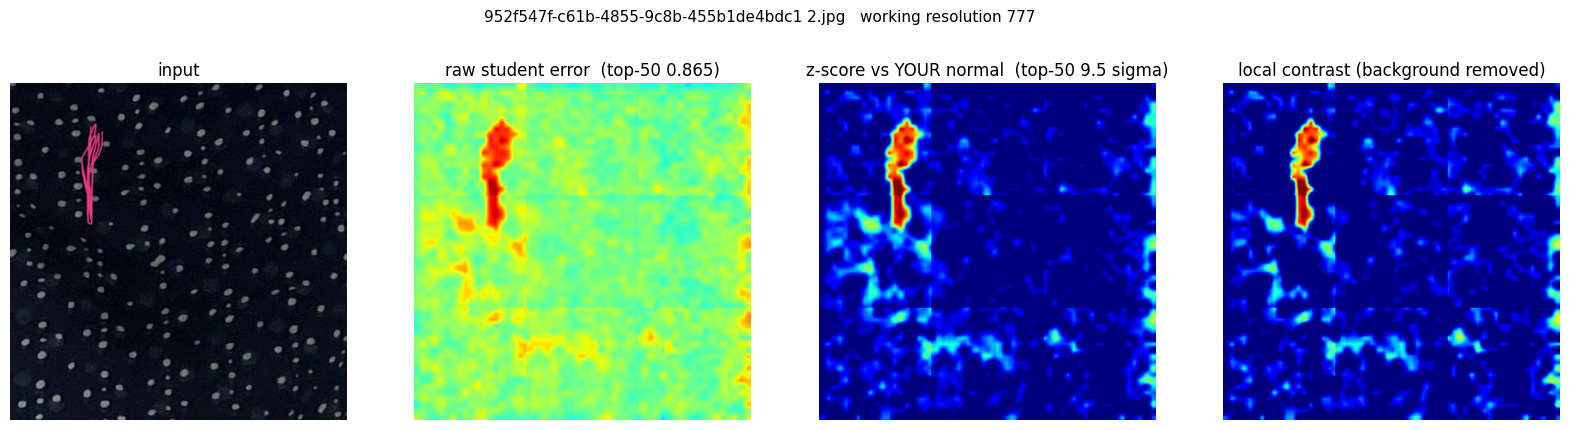

952f547f-c61b-4855-9c8b-455b1de4bdc1 2.jpg: raw score 0.8651 | z-score 9.51 sigma | saved /kaggle/working/student_only_952f547f-c61b-4855-9c8b-455b1de4bdc1 2.png


In [7]:
# ============================================================
# Trained Fabric student, NO fine-tuning, on YOUR OWN fabric photo(s).
# The student and teacher weights are never changed. We only change how the
# output is read, using your defect-free photo(s) for calibration:
#   1. pick the working resolution at which the student finds your fabric most familiar
#   2. flip test-time averaging (4 views) to cut noise
#   3. z-score the error against the error on YOUR normal photo(s)
#   4. a "local contrast" map that removes the broad high background
# Paste into a Kaggle notebook cell (Internet ON for DINOv2, GPU recommended).
# ============================================================
import os, glob, shutil
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from scipy.ndimage import gaussian_filter
import matplotlib.pyplot as plt
try:
    from pillow_heif import register_heif_opener; register_heif_opener()
except Exception:
    pass

# ---------------- EDIT THESE ----------------
CKPT_PATH   = "/kaggle/input/datasets/jindwork/dino-fabric/dinov2_teacher_student_fabric"
NORMAL_PATH = "/kaggle/input/datasets/jindwork/normal-fabric/952f547f-c61b-4855-9c8b-455b1de4bdc1 3.JPG"                          # file or folder: defect-free photo(s) of YOUR fabric
TEST_PATH   = "/kaggle/input/datasets/jindwork/fabriccc234"        # file or folder to check
SCALES      = [777, 1036, 1295, 1554]   # working resolutions to try (1036 = the paper's setting)
FORCE_SRC   = None                      # e.g. 1036 to skip the scale search
USE_TTA     = True                      # average over flips
CONTRAST_SIGMA = 40                     # blur size (on the 448 map) for the local-contrast panel
MAX_NORMALS = 10
# --------------------------------------------

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
TILE, STRIDE = 518, 392
PATCH, EMBED, DEPTH, HEADS = 14, 384, 4, 6
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
EXT = (".png", ".jpg", ".jpeg", ".bmp", ".webp", ".heic")

def list_images(p):
    if os.path.isdir(p):
        return sorted(f for f in glob.glob(os.path.join(p, "**", "*"), recursive=True) if f.lower().endswith(EXT))
    return [p]

# ---------- load the trained student (unchanged) ----------
def resolve_ckpt(path):
    if os.path.isdir(path):
        pts = glob.glob(os.path.join(path, "**", "*.pt"), recursive=True) + \
              glob.glob(os.path.join(path, "**", "*.pth"), recursive=True)
        if pts:
            return pts[0]
        parent, name = os.path.split(path.rstrip("/"))
        out_stem = f"/kaggle/working/{name}_rezipped"
        shutil.make_archive(out_stem, "zip", root_dir=parent, base_dir=name)
        os.replace(out_stem + ".zip", out_stem + ".pt")
        return out_stem + ".pt"
    return path

raw = torch.load(resolve_ckpt(CKPT_PATH), map_location="cpu")
state = raw
if isinstance(raw, dict):
    for k in ("student_state_dict", "student", "model", "state_dict", "model_state_dict"):
        if k in raw and isinstance(raw[k], dict):
            state = raw[k]; break
state = {k.replace("module.", "", 1): v for k, v in state.items()}

class Student(nn.Module):
    def __init__(self):
        super().__init__()
        self.patch_embed = nn.Conv2d(3, EMBED, kernel_size=PATCH, stride=PATCH)
        self.pos_embed = nn.Parameter(torch.zeros(1, (TILE // PATCH) ** 2, EMBED))
        layer = nn.TransformerEncoderLayer(d_model=EMBED, nhead=HEADS, dim_feedforward=EMBED * 4, batch_first=True)
        self.blocks = nn.TransformerEncoder(layer, num_layers=DEPTH)
        self.head = nn.Linear(EMBED, 768)
    def forward(self, x):
        x = self.patch_embed(x).flatten(2).transpose(1, 2) + self.pos_embed
        return self.head(self.blocks(x))

student = Student()
try:
    student.load_state_dict(state, strict=True)
except RuntimeError as e:
    ck, md = list(state.items()), list(student.state_dict().items())
    if len(ck) == len(md) and all(a[1].shape == b[1].shape for a, b in zip(ck, md)):
        student.load_state_dict({b[0]: a[1] for a, b in zip(ck, md)})
    else:
        raise e
student = student.to(DEVICE).eval()
for q in student.parameters(): q.requires_grad = False
dinov2 = torch.hub.load("facebookresearch/dinov2", "dinov2_vitb14").to(DEVICE).eval()
for q in dinov2.parameters(): q.requires_grad = False

# ---------- anomaly map at a chosen resolution / flip ----------
def _coords(n, tile, stride):
    xs = list(range(0, n - tile + 1, stride))
    return xs + [n - tile] if xs[-1] != n - tile else xs

_img_cache = {}
def load_rgb(path):
    if path not in _img_cache:
        _img_cache[path] = Image.open(path).convert("RGB")
    return _img_cache[path]

@torch.no_grad()
def map448(path, src, flip=""):
    """student-vs-teacher error map at working resolution `src`, returned on the 448 grid (flip undone)."""
    im = load_rgb(path).resize((src, src), Image.BILINEAR)
    x = torch.from_numpy(np.array(im)).float().permute(2, 0, 1) / 255
    if "h" in flip: x = torch.flip(x, dims=[2])
    if "v" in flip: x = torch.flip(x, dims=[1])
    x = (x - MEAN) / STD
    coords = [(y, xx) for y in _coords(src, TILE, STRIDE) for xx in _coords(src, TILE, STRIDE)]
    acc = np.zeros((src, src), np.float32); cnt = np.zeros_like(acc)
    for i in range(0, len(coords), 8):
        cs = coords[i:i + 8]
        b = torch.stack([x[:, y:y + TILE, xx:xx + TILE] for y, xx in cs]).to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
            t = dinov2.forward_features(b)["x_norm_patchtokens"]
            s = student(b)
        err = 1 - F.cosine_similarity(s.float(), t.float(), dim=-1)
        g = int(err.shape[1] ** 0.5)
        err = F.interpolate(err.view(-1, 1, g, g), size=(TILE, TILE), mode="bilinear", align_corners=False)[:, 0].cpu().numpy()
        for (y, xx), m in zip(cs, err):
            acc[y:y + TILE, xx:xx + TILE] += m; cnt[y:y + TILE, xx:xx + TILE] += 1
    m = F.interpolate(torch.from_numpy(acc / cnt)[None, None], size=(448, 448), mode="bilinear",
                      align_corners=False, antialias=True)[0, 0].numpy()
    if "h" in flip: m = m[:, ::-1]
    if "v" in flip: m = m[::-1, :]
    return np.ascontiguousarray(m)

def tta_map(path, src):
    flips = ["", "h", "v", "hv"] if USE_TTA else [""]
    return np.mean([map448(path, src, f) for f in flips], axis=0)

def top50(m):
    c = m[10:-10, 10:-10].ravel()
    return float(np.partition(c, -50)[-50:].mean())

# ---------- 1. choose the resolution from YOUR normal photo(s) ----------
normals = list_images(NORMAL_PATH)[:MAX_NORMALS]
assert normals, f"No normal images at {NORMAL_PATH}"
if FORCE_SRC:
    SRC = FORCE_SRC
else:
    print("Mean student error on your normal photo(s) at each resolution (lower = more familiar):")
    res = {}
    for s in SCALES:
        res[s] = float(np.mean([map448(p, s)[10:-10, 10:-10].mean() for p in normals]))
        print(f"  {s}: {res[s]:.4f}")
    SRC = min(res, key=res.get)
    print(f"-> using {SRC}.  (Caution: the lowest error can also mean a blurrier view. Set FORCE_SRC to override.)")

# ---------- 2. error statistics on YOUR normal photo(s) ----------
ref = np.concatenate([tta_map(p, SRC)[10:-10, 10:-10].ravel() for p in normals])
REF_MEAN, REF_STD = float(ref.mean()), float(ref.std() + 1e-8)
print(f"your normal photo(s): pixel error mean {REF_MEAN:.4f}, std {REF_STD:.4f}, 99.9th pct {np.percentile(ref, 99.9):.4f}")

# ---------- 3. test photo(s) ----------
for p in list_images(TEST_PATH):
    m = tta_map(p, SRC)
    z = (m - REF_MEAN) / REF_STD                                   # error in "normal-photo standard deviations"
    lc = m - gaussian_filter(m, sigma=CONTRAST_SIGMA)             # local contrast: remove the broad background
    raw_score, z_score = top50(m), top50(z)
    orig = np.array(load_rgb(p).resize((448, 448)))
    fig, ax = plt.subplots(1, 4, figsize=(20, 5))
    ax[0].imshow(orig); ax[0].set_title("input")
    ax[1].imshow(m, cmap="jet", vmin=0, vmax=max(m.max(), 1e-6)); ax[1].set_title(f"raw student error  (top-50 {raw_score:.3f})")
    ax[2].imshow(z, cmap="jet", vmin=0, vmax=max(5.0, float(np.percentile(z, 99.9)))); ax[2].set_title(f"z-score vs YOUR normal  (top-50 {z_score:.1f} sigma)")
    ax[3].imshow(lc, cmap="jet", vmin=0, vmax=max(float(np.percentile(lc, 99.9)), 1e-6)); ax[3].set_title("local contrast (background removed)")
    for a in ax: a.axis("off")
    fig.suptitle(f"{os.path.basename(p)}   working resolution {SRC}", fontsize=11)
    out = f"/kaggle/working/student_only_{os.path.splitext(os.path.basename(p))[0]}.png"
    fig.savefig(out, bbox_inches="tight"); plt.show()
    print(f"{os.path.basename(p)}: raw score {raw_score:.4f} | z-score {z_score:.2f} sigma | saved {out}")

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


Mean student error on your normal photo(s) at each resolution (lower = more familiar):
  777: 0.4686
  1036: 0.4813
  1295: 0.4867
  1554: 0.4911
-> using 777.  (Caution: the lowest error can also mean a blurrier view. Set FORCE_SRC to override.)
your normal photo(s): pixel error mean 0.4615, std 0.0425, 99.9th pct 0.6512


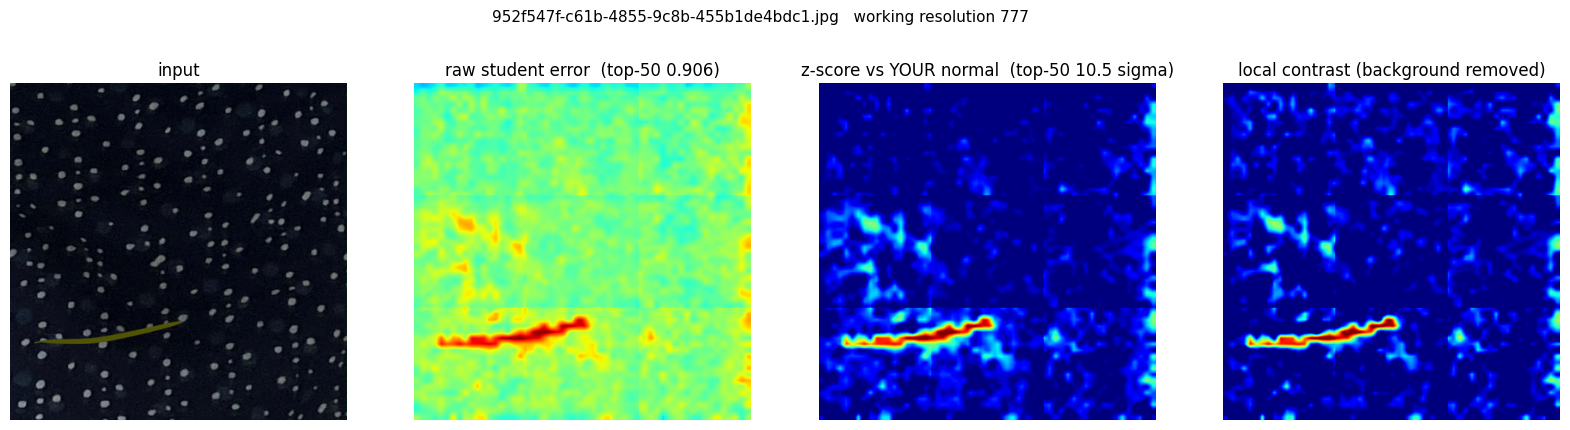

952f547f-c61b-4855-9c8b-455b1de4bdc1.jpg: raw score 0.9061 | z-score 10.47 sigma | saved /kaggle/working/student_only_952f547f-c61b-4855-9c8b-455b1de4bdc1.png


In [9]:
# ============================================================
# Trained Fabric student, NO fine-tuning, on YOUR OWN fabric photo(s).
# The student and teacher weights are never changed. We only change how the
# output is read, using your defect-free photo(s) for calibration:
#   1. pick the working resolution at which the student finds your fabric most familiar
#   2. flip test-time averaging (4 views) to cut noise
#   3. z-score the error against the error on YOUR normal photo(s)
#   4. a "local contrast" map that removes the broad high background
# Paste into a Kaggle notebook cell (Internet ON for DINOv2, GPU recommended).
# ============================================================
import os, glob, shutil
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from scipy.ndimage import gaussian_filter
import matplotlib.pyplot as plt
try:
    from pillow_heif import register_heif_opener; register_heif_opener()
except Exception:
    pass

# ---------------- EDIT THESE ----------------
CKPT_PATH   = "/kaggle/input/datasets/jindwork/dino-fabric/dinov2_teacher_student_fabric"
NORMAL_PATH = "/kaggle/input/datasets/jindwork/normal-fabric/952f547f-c61b-4855-9c8b-455b1de4bdc1 3.JPG"                          # file or folder: defect-free photo(s) of YOUR fabric
TEST_PATH   = "/kaggle/input/datasets/jindwork/more-data/952f547f-c61b-4855-9c8b-455b1de4bdc1.jpg"        # file or folder to check
SCALES      = [777, 1036, 1295, 1554]   # working resolutions to try (1036 = the paper's setting)
FORCE_SRC   = None                      # e.g. 1036 to skip the scale search
USE_TTA     = True                      # average over flips
CONTRAST_SIGMA = 40                     # blur size (on the 448 map) for the local-contrast panel
MAX_NORMALS = 10
# --------------------------------------------

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
TILE, STRIDE = 518, 392
PATCH, EMBED, DEPTH, HEADS = 14, 384, 4, 6
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
EXT = (".png", ".jpg", ".jpeg", ".bmp", ".webp", ".heic")

def list_images(p):
    if os.path.isdir(p):
        return sorted(f for f in glob.glob(os.path.join(p, "**", "*"), recursive=True) if f.lower().endswith(EXT))
    return [p]

# ---------- load the trained student (unchanged) ----------
def resolve_ckpt(path):
    if os.path.isdir(path):
        pts = glob.glob(os.path.join(path, "**", "*.pt"), recursive=True) + \
              glob.glob(os.path.join(path, "**", "*.pth"), recursive=True)
        if pts:
            return pts[0]
        parent, name = os.path.split(path.rstrip("/"))
        out_stem = f"/kaggle/working/{name}_rezipped"
        shutil.make_archive(out_stem, "zip", root_dir=parent, base_dir=name)
        os.replace(out_stem + ".zip", out_stem + ".pt")
        return out_stem + ".pt"
    return path

raw = torch.load(resolve_ckpt(CKPT_PATH), map_location="cpu")
state = raw
if isinstance(raw, dict):
    for k in ("student_state_dict", "student", "model", "state_dict", "model_state_dict"):
        if k in raw and isinstance(raw[k], dict):
            state = raw[k]; break
state = {k.replace("module.", "", 1): v for k, v in state.items()}

class Student(nn.Module):
    def __init__(self):
        super().__init__()
        self.patch_embed = nn.Conv2d(3, EMBED, kernel_size=PATCH, stride=PATCH)
        self.pos_embed = nn.Parameter(torch.zeros(1, (TILE // PATCH) ** 2, EMBED))
        layer = nn.TransformerEncoderLayer(d_model=EMBED, nhead=HEADS, dim_feedforward=EMBED * 4, batch_first=True)
        self.blocks = nn.TransformerEncoder(layer, num_layers=DEPTH)
        self.head = nn.Linear(EMBED, 768)
    def forward(self, x):
        x = self.patch_embed(x).flatten(2).transpose(1, 2) + self.pos_embed
        return self.head(self.blocks(x))

student = Student()
try:
    student.load_state_dict(state, strict=True)
except RuntimeError as e:
    ck, md = list(state.items()), list(student.state_dict().items())
    if len(ck) == len(md) and all(a[1].shape == b[1].shape for a, b in zip(ck, md)):
        student.load_state_dict({b[0]: a[1] for a, b in zip(ck, md)})
    else:
        raise e
student = student.to(DEVICE).eval()
for q in student.parameters(): q.requires_grad = False
dinov2 = torch.hub.load("facebookresearch/dinov2", "dinov2_vitb14").to(DEVICE).eval()
for q in dinov2.parameters(): q.requires_grad = False

# ---------- anomaly map at a chosen resolution / flip ----------
def _coords(n, tile, stride):
    xs = list(range(0, n - tile + 1, stride))
    return xs + [n - tile] if xs[-1] != n - tile else xs

_img_cache = {}
def load_rgb(path):
    if path not in _img_cache:
        _img_cache[path] = Image.open(path).convert("RGB")
    return _img_cache[path]

@torch.no_grad()
def map448(path, src, flip=""):
    """student-vs-teacher error map at working resolution `src`, returned on the 448 grid (flip undone)."""
    im = load_rgb(path).resize((src, src), Image.BILINEAR)
    x = torch.from_numpy(np.array(im)).float().permute(2, 0, 1) / 255
    if "h" in flip: x = torch.flip(x, dims=[2])
    if "v" in flip: x = torch.flip(x, dims=[1])
    x = (x - MEAN) / STD
    coords = [(y, xx) for y in _coords(src, TILE, STRIDE) for xx in _coords(src, TILE, STRIDE)]
    acc = np.zeros((src, src), np.float32); cnt = np.zeros_like(acc)
    for i in range(0, len(coords), 8):
        cs = coords[i:i + 8]
        b = torch.stack([x[:, y:y + TILE, xx:xx + TILE] for y, xx in cs]).to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
            t = dinov2.forward_features(b)["x_norm_patchtokens"]
            s = student(b)
        err = 1 - F.cosine_similarity(s.float(), t.float(), dim=-1)
        g = int(err.shape[1] ** 0.5)
        err = F.interpolate(err.view(-1, 1, g, g), size=(TILE, TILE), mode="bilinear", align_corners=False)[:, 0].cpu().numpy()
        for (y, xx), m in zip(cs, err):
            acc[y:y + TILE, xx:xx + TILE] += m; cnt[y:y + TILE, xx:xx + TILE] += 1
    m = F.interpolate(torch.from_numpy(acc / cnt)[None, None], size=(448, 448), mode="bilinear",
                      align_corners=False, antialias=True)[0, 0].numpy()
    if "h" in flip: m = m[:, ::-1]
    if "v" in flip: m = m[::-1, :]
    return np.ascontiguousarray(m)

def tta_map(path, src):
    flips = ["", "h", "v", "hv"] if USE_TTA else [""]
    return np.mean([map448(path, src, f) for f in flips], axis=0)

def top50(m):
    c = m[10:-10, 10:-10].ravel()
    return float(np.partition(c, -50)[-50:].mean())

# ---------- 1. choose the resolution from YOUR normal photo(s) ----------
normals = list_images(NORMAL_PATH)[:MAX_NORMALS]
assert normals, f"No normal images at {NORMAL_PATH}"
if FORCE_SRC:
    SRC = FORCE_SRC
else:
    print("Mean student error on your normal photo(s) at each resolution (lower = more familiar):")
    res = {}
    for s in SCALES:
        res[s] = float(np.mean([map448(p, s)[10:-10, 10:-10].mean() for p in normals]))
        print(f"  {s}: {res[s]:.4f}")
    SRC = min(res, key=res.get)
    print(f"-> using {SRC}.  (Caution: the lowest error can also mean a blurrier view. Set FORCE_SRC to override.)")

# ---------- 2. error statistics on YOUR normal photo(s) ----------
ref = np.concatenate([tta_map(p, SRC)[10:-10, 10:-10].ravel() for p in normals])
REF_MEAN, REF_STD = float(ref.mean()), float(ref.std() + 1e-8)
print(f"your normal photo(s): pixel error mean {REF_MEAN:.4f}, std {REF_STD:.4f}, 99.9th pct {np.percentile(ref, 99.9):.4f}")

# ---------- 3. test photo(s) ----------
for p in list_images(TEST_PATH):
    m = tta_map(p, SRC)
    z = (m - REF_MEAN) / REF_STD                                   # error in "normal-photo standard deviations"
    lc = m - gaussian_filter(m, sigma=CONTRAST_SIGMA)             # local contrast: remove the broad background
    raw_score, z_score = top50(m), top50(z)
    orig = np.array(load_rgb(p).resize((448, 448)))
    fig, ax = plt.subplots(1, 4, figsize=(20, 5))
    ax[0].imshow(orig); ax[0].set_title("input")
    ax[1].imshow(m, cmap="jet", vmin=0, vmax=max(m.max(), 1e-6)); ax[1].set_title(f"raw student error  (top-50 {raw_score:.3f})")
    ax[2].imshow(z, cmap="jet", vmin=0, vmax=max(5.0, float(np.percentile(z, 99.9)))); ax[2].set_title(f"z-score vs YOUR normal  (top-50 {z_score:.1f} sigma)")
    ax[3].imshow(lc, cmap="jet", vmin=0, vmax=max(float(np.percentile(lc, 99.9)), 1e-6)); ax[3].set_title("local contrast (background removed)")
    for a in ax: a.axis("off")
    fig.suptitle(f"{os.path.basename(p)}   working resolution {SRC}", fontsize=11)
    out = f"/kaggle/working/student_only_{os.path.splitext(os.path.basename(p))[0]}.png"
    fig.savefig(out, bbox_inches="tight"); plt.show()
    print(f"{os.path.basename(p)}: raw score {raw_score:.4f} | z-score {z_score:.2f} sigma | saved {out}")

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


Mean student error on your normal photo(s) at each resolution (lower = more familiar):
  777: 0.4686
  1036: 0.4813
  1295: 0.4867
  1554: 0.4911
-> using 777.  (Caution: the lowest error can also mean a blurrier view. Set FORCE_SRC to override.)
your normal photo(s): pixel error mean 0.4615, std 0.0425, 99.9th pct 0.6512


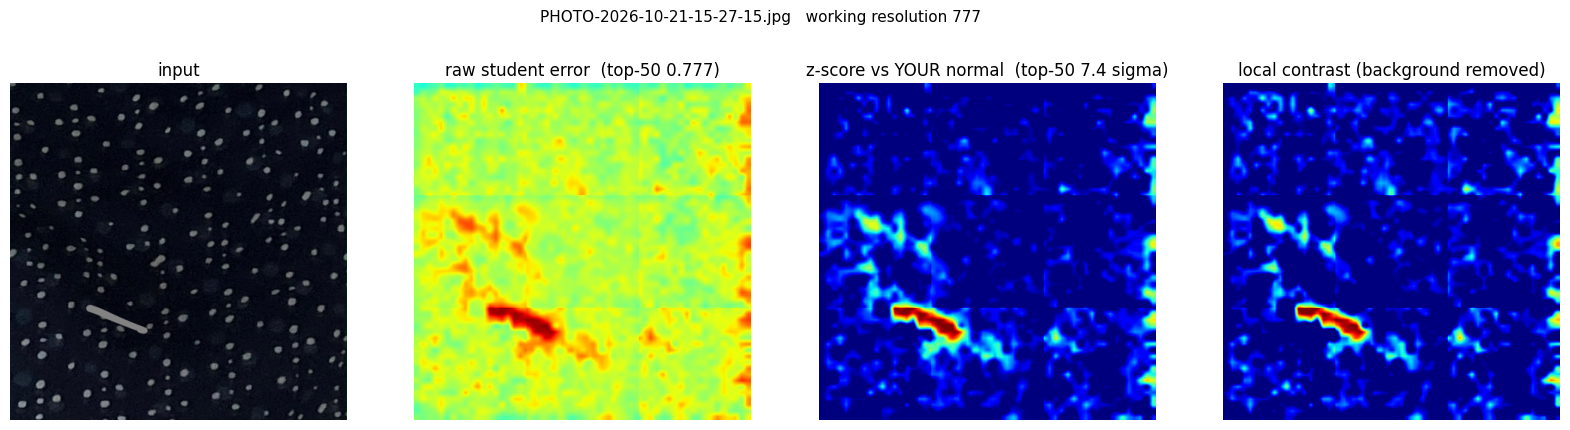

PHOTO-2026-10-21-15-27-15.jpg: raw score 0.7768 | z-score 7.43 sigma | saved /kaggle/working/student_only_PHOTO-2026-10-21-15-27-15.png


In [10]:
# ============================================================
# Trained Fabric student, NO fine-tuning, on YOUR OWN fabric photo(s).
# The student and teacher weights are never changed. We only change how the
# output is read, using your defect-free photo(s) for calibration:
#   1. pick the working resolution at which the student finds your fabric most familiar
#   2. flip test-time averaging (4 views) to cut noise
#   3. z-score the error against the error on YOUR normal photo(s)
#   4. a "local contrast" map that removes the broad high background
# Paste into a Kaggle notebook cell (Internet ON for DINOv2, GPU recommended).
# ============================================================
import os, glob, shutil
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from scipy.ndimage import gaussian_filter
import matplotlib.pyplot as plt
try:
    from pillow_heif import register_heif_opener; register_heif_opener()
except Exception:
    pass

# ---------------- EDIT THESE ----------------
CKPT_PATH   = "/kaggle/input/datasets/jindwork/dino-fabric/dinov2_teacher_student_fabric"
NORMAL_PATH = "/kaggle/input/datasets/jindwork/normal-fabric/952f547f-c61b-4855-9c8b-455b1de4bdc1 3.JPG"                          # file or folder: defect-free photo(s) of YOUR fabric
TEST_PATH   = "/kaggle/input/datasets/jindwork/more-data/PHOTO-2026-10-21-15-27-15.jpg"        # file or folder to check
SCALES      = [777, 1036, 1295, 1554]   # working resolutions to try (1036 = the paper's setting)
FORCE_SRC   = None                      # e.g. 1036 to skip the scale search
USE_TTA     = True                      # average over flips
CONTRAST_SIGMA = 40                     # blur size (on the 448 map) for the local-contrast panel
MAX_NORMALS = 10
# --------------------------------------------

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
TILE, STRIDE = 518, 392
PATCH, EMBED, DEPTH, HEADS = 14, 384, 4, 6
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
EXT = (".png", ".jpg", ".jpeg", ".bmp", ".webp", ".heic")

def list_images(p):
    if os.path.isdir(p):
        return sorted(f for f in glob.glob(os.path.join(p, "**", "*"), recursive=True) if f.lower().endswith(EXT))
    return [p]

# ---------- load the trained student (unchanged) ----------
def resolve_ckpt(path):
    if os.path.isdir(path):
        pts = glob.glob(os.path.join(path, "**", "*.pt"), recursive=True) + \
              glob.glob(os.path.join(path, "**", "*.pth"), recursive=True)
        if pts:
            return pts[0]
        parent, name = os.path.split(path.rstrip("/"))
        out_stem = f"/kaggle/working/{name}_rezipped"
        shutil.make_archive(out_stem, "zip", root_dir=parent, base_dir=name)
        os.replace(out_stem + ".zip", out_stem + ".pt")
        return out_stem + ".pt"
    return path

raw = torch.load(resolve_ckpt(CKPT_PATH), map_location="cpu")
state = raw
if isinstance(raw, dict):
    for k in ("student_state_dict", "student", "model", "state_dict", "model_state_dict"):
        if k in raw and isinstance(raw[k], dict):
            state = raw[k]; break
state = {k.replace("module.", "", 1): v for k, v in state.items()}

class Student(nn.Module):
    def __init__(self):
        super().__init__()
        self.patch_embed = nn.Conv2d(3, EMBED, kernel_size=PATCH, stride=PATCH)
        self.pos_embed = nn.Parameter(torch.zeros(1, (TILE // PATCH) ** 2, EMBED))
        layer = nn.TransformerEncoderLayer(d_model=EMBED, nhead=HEADS, dim_feedforward=EMBED * 4, batch_first=True)
        self.blocks = nn.TransformerEncoder(layer, num_layers=DEPTH)
        self.head = nn.Linear(EMBED, 768)
    def forward(self, x):
        x = self.patch_embed(x).flatten(2).transpose(1, 2) + self.pos_embed
        return self.head(self.blocks(x))

student = Student()
try:
    student.load_state_dict(state, strict=True)
except RuntimeError as e:
    ck, md = list(state.items()), list(student.state_dict().items())
    if len(ck) == len(md) and all(a[1].shape == b[1].shape for a, b in zip(ck, md)):
        student.load_state_dict({b[0]: a[1] for a, b in zip(ck, md)})
    else:
        raise e
student = student.to(DEVICE).eval()
for q in student.parameters(): q.requires_grad = False
dinov2 = torch.hub.load("facebookresearch/dinov2", "dinov2_vitb14").to(DEVICE).eval()
for q in dinov2.parameters(): q.requires_grad = False

# ---------- anomaly map at a chosen resolution / flip ----------
def _coords(n, tile, stride):
    xs = list(range(0, n - tile + 1, stride))
    return xs + [n - tile] if xs[-1] != n - tile else xs

_img_cache = {}
def load_rgb(path):
    if path not in _img_cache:
        _img_cache[path] = Image.open(path).convert("RGB")
    return _img_cache[path]

@torch.no_grad()
def map448(path, src, flip=""):
    """student-vs-teacher error map at working resolution `src`, returned on the 448 grid (flip undone)."""
    im = load_rgb(path).resize((src, src), Image.BILINEAR)
    x = torch.from_numpy(np.array(im)).float().permute(2, 0, 1) / 255
    if "h" in flip: x = torch.flip(x, dims=[2])
    if "v" in flip: x = torch.flip(x, dims=[1])
    x = (x - MEAN) / STD
    coords = [(y, xx) for y in _coords(src, TILE, STRIDE) for xx in _coords(src, TILE, STRIDE)]
    acc = np.zeros((src, src), np.float32); cnt = np.zeros_like(acc)
    for i in range(0, len(coords), 8):
        cs = coords[i:i + 8]
        b = torch.stack([x[:, y:y + TILE, xx:xx + TILE] for y, xx in cs]).to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
            t = dinov2.forward_features(b)["x_norm_patchtokens"]
            s = student(b)
        err = 1 - F.cosine_similarity(s.float(), t.float(), dim=-1)
        g = int(err.shape[1] ** 0.5)
        err = F.interpolate(err.view(-1, 1, g, g), size=(TILE, TILE), mode="bilinear", align_corners=False)[:, 0].cpu().numpy()
        for (y, xx), m in zip(cs, err):
            acc[y:y + TILE, xx:xx + TILE] += m; cnt[y:y + TILE, xx:xx + TILE] += 1
    m = F.interpolate(torch.from_numpy(acc / cnt)[None, None], size=(448, 448), mode="bilinear",
                      align_corners=False, antialias=True)[0, 0].numpy()
    if "h" in flip: m = m[:, ::-1]
    if "v" in flip: m = m[::-1, :]
    return np.ascontiguousarray(m)

def tta_map(path, src):
    flips = ["", "h", "v", "hv"] if USE_TTA else [""]
    return np.mean([map448(path, src, f) for f in flips], axis=0)

def top50(m):
    c = m[10:-10, 10:-10].ravel()
    return float(np.partition(c, -50)[-50:].mean())

# ---------- 1. choose the resolution from YOUR normal photo(s) ----------
normals = list_images(NORMAL_PATH)[:MAX_NORMALS]
assert normals, f"No normal images at {NORMAL_PATH}"
if FORCE_SRC:
    SRC = FORCE_SRC
else:
    print("Mean student error on your normal photo(s) at each resolution (lower = more familiar):")
    res = {}
    for s in SCALES:
        res[s] = float(np.mean([map448(p, s)[10:-10, 10:-10].mean() for p in normals]))
        print(f"  {s}: {res[s]:.4f}")
    SRC = min(res, key=res.get)
    print(f"-> using {SRC}.  (Caution: the lowest error can also mean a blurrier view. Set FORCE_SRC to override.)")

# ---------- 2. error statistics on YOUR normal photo(s) ----------
ref = np.concatenate([tta_map(p, SRC)[10:-10, 10:-10].ravel() for p in normals])
REF_MEAN, REF_STD = float(ref.mean()), float(ref.std() + 1e-8)
print(f"your normal photo(s): pixel error mean {REF_MEAN:.4f}, std {REF_STD:.4f}, 99.9th pct {np.percentile(ref, 99.9):.4f}")

# ---------- 3. test photo(s) ----------
for p in list_images(TEST_PATH):
    m = tta_map(p, SRC)
    z = (m - REF_MEAN) / REF_STD                                   # error in "normal-photo standard deviations"
    lc = m - gaussian_filter(m, sigma=CONTRAST_SIGMA)             # local contrast: remove the broad background
    raw_score, z_score = top50(m), top50(z)
    orig = np.array(load_rgb(p).resize((448, 448)))
    fig, ax = plt.subplots(1, 4, figsize=(20, 5))
    ax[0].imshow(orig); ax[0].set_title("input")
    ax[1].imshow(m, cmap="jet", vmin=0, vmax=max(m.max(), 1e-6)); ax[1].set_title(f"raw student error  (top-50 {raw_score:.3f})")
    ax[2].imshow(z, cmap="jet", vmin=0, vmax=max(5.0, float(np.percentile(z, 99.9)))); ax[2].set_title(f"z-score vs YOUR normal  (top-50 {z_score:.1f} sigma)")
    ax[3].imshow(lc, cmap="jet", vmin=0, vmax=max(float(np.percentile(lc, 99.9)), 1e-6)); ax[3].set_title("local contrast (background removed)")
    for a in ax: a.axis("off")
    fig.suptitle(f"{os.path.basename(p)}   working resolution {SRC}", fontsize=11)
    out = f"/kaggle/working/student_only_{os.path.splitext(os.path.basename(p))[0]}.png"
    fig.savefig(out, bbox_inches="tight"); plt.show()
    print(f"{os.path.basename(p)}: raw score {raw_score:.4f} | z-score {z_score:.2f} sigma | saved {out}")